# Customer Change Request Simulator

## Project Goal

Simulate how a customer change request propagates through different departments in a manufacturing company.

### Scenario

A customer requests changes after production has already started.

The simulator helps visualize:

- Engineering impact
- Production impact
- Testing impact
- Delivery impact

before a final decision is made.

In [1]:
import pandas as pd

dependency_map = pd.DataFrame({

    "Step": [
        1, 2, 3, 4, 5, 6, 7
    ],

    "Department": [
        "Sales",
        "Engineering",
        "Procurement",
        "Production",
        "Testing",
        "Delivery",
        "Management"
    ],

    "Responsibility": [
        "Receive Change Request",
        "Evaluate Technical Feasibility",
        "Check Component Availability",
        "Estimate Rework",
        "Estimate Additional Testing",
        "Assess Delivery Impact",
        "Approve Final Decision"
    ]
})

dependency_map

,Step,Department,Responsibility
0,1,Sales,Receive Change Request
1,2,Engineering,Evaluate Technical Feasibility
2,3,Procurement,Check Component Availability
3,4,Production,Estimate Rework
4,5,Testing,Estimate Additional Testing
5,6,Delivery,Assess Delivery Impact
6,7,Management,Approve Final Decision


# Dependency Chain Visualization

The diagram below illustrates how the consequences of a customer change request propagate through the organisation.

Each department depends on information or decisions generated by the previous department.

A disruption at one stage can create downstream impacts on cost, schedule, quality, and delivery performance.

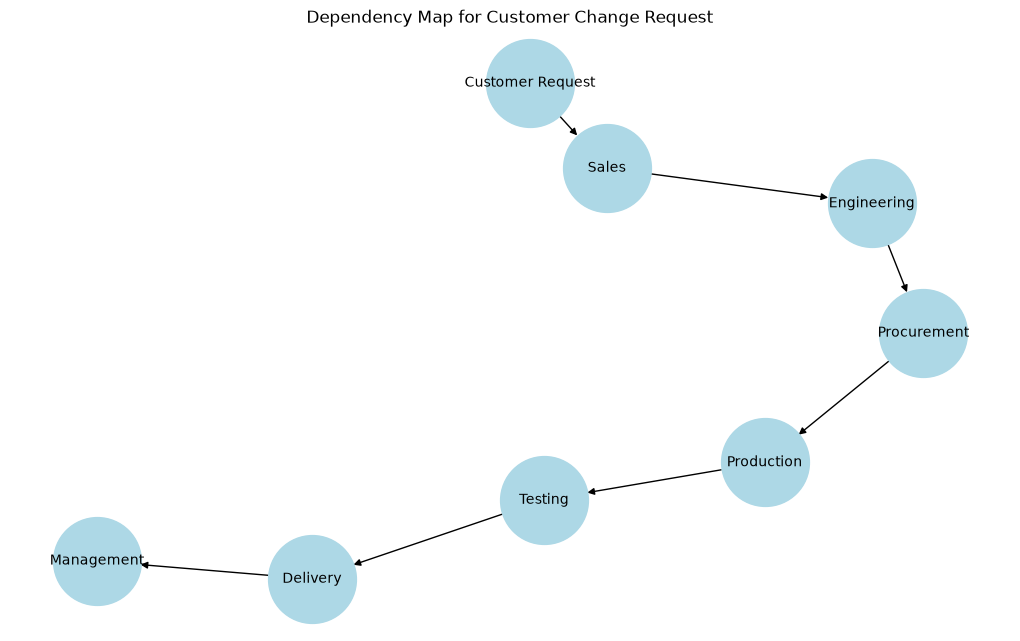

In [2]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

G.add_edges_from([
    ("Customer Request", "Sales"),
    ("Sales", "Engineering"),
    ("Engineering", "Procurement"),
    ("Procurement", "Production"),
    ("Production", "Testing"),
    ("Testing", "Delivery"),
    ("Delivery", "Management")
])

plt.figure(figsize=(10,6))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=4000,
    node_color="lightblue",
    arrows=True,
    font_size=10
)

plt.title("Dependency Map for Customer Change Request")

plt.show()

# Assumptions

The impact levels used in this prototype are based on engineering reasoning and decision archaeology assumptions.

The values do not represent a specific company.

They represent plausible relationships observed in manufacturing environments:

- Early changes usually have lower impact.
- Late changes usually have higher impact.
- Component shortages increase risk.
- Fixed deadlines increase schedule pressure.

Future versions will validate these assumptions through interviews and workshops with industry professionals.

# Impact Matrix

The simulator estimates how different factors influence the organisation.

Impact Levels

- Low
- Medium
- High

These impact levels are based on engineering reasoning and project assumptions.


In [3]:
import pandas as pd

impact_matrix = pd.DataFrame({

    "Factor": [
        "Production Stage",
        "Production Stage",
        "Production Stage"
    ],

    "Condition": [
        "Design",
        "Assembly",
        "Testing"
    ],

    "Impact Level": [
        "Low",
        "Medium",
        "High"
    ]
})

impact_matrix

,Factor,Condition,Impact Level
0,Production Stage,Design,Low
1,Production Stage,Assembly,Medium
2,Production Stage,Testing,High


# Simulation Factors

The simulator evaluates the impact of a customer change request using four key dimensions:

1. Production Stage
2. Component Availability
3. Production Workload
4. Delivery Deadline

Each factor contributes to the final risk and impact assessment.

In [4]:
knowledge_model = pd.DataFrame({

    "Factor": [
        "Production Stage",
        "Production Stage",
        "Production Stage",
        "Component Availability",
        "Component Availability",
        "Component Availability",
        "Production Workload",
        "Production Workload",
        "Production Workload",
        "Delivery Deadline",
        "Delivery Deadline"
    ],

    "Condition": [
        "Design",
        "Assembly",
        "Testing",
        "Available",
        "Limited",
        "Unavailable",
        "Low",
        "Medium",
        "High",
        "Flexible",
        "Fixed"
    ],

    "Impact Level": [
        "Low",
        "Medium",
        "High",
        "Low",
        "Medium",
        "High",
        "Low",
        "Medium",
        "High",
        "Low",
        "High"
    ]
})

knowledge_model

,Factor,Condition,Impact Level
0,Production Stage,Design,Low
1,Production Stage,Assembly,Medium
2,Production Stage,Testing,High
3,Component Availability,Available,Low
4,Component Availability,Limited,Medium
5,Component Availability,Unavailable,High
6,Production Workload,Low,Low
7,Production Workload,Medium,Medium
8,Production Workload,High,High
9,Delivery Deadline,Flexible,Low


# Impact Interpretation

The simulator converts qualitative impact levels into business consequences.

This allows organisational effects to be explained consistently across scenarios.

In [26]:
impact_interpretation = pd.DataFrame({

    "Impact Level": [
        "Low",
        "Medium",
        "High"
    ],

    "Engineering Impact": [
        "Minor design updates",
        "Moderate redesign effort",
        "Major redesign effort"
    ],

    "Production Impact": [
        "Minimal rework",
        "Partial rework required",
        "Extensive rework required"
    ],

    "Delivery Risk": [
        "Low",
        "Medium",
        "High"
    ]
})

impact_interpretation

,Impact Level,Engineering Impact,Production Impact,Delivery Risk
0,Low,Minor design updates,Minimal rework,Low
1,Medium,Moderate redesign effort,Partial rework required,Medium
2,High,Major redesign effort,Extensive rework required,High


# Scenario Simulation

The simulator evaluates a scenario by combining multiple organisational factors.

Each factor contributes an impact level:

- Low
- Medium
- High

The overall impact is determined by the combination of all selected conditions.

In [49]:
production_stage = input(
    "Enter Production Stage (Design, Assembly, Testing): "
)

component_availability = input(
    "Enter Component Availability (Available, Limited, Unavailable): "
)

production_workload = input(
    "Enter Production Workload (Low, Medium, High): "
)

delivery_deadline = input(
    "Enter Delivery Deadline (Flexible, Fixed): "
)

scenario = {

    "Production Stage": production_stage,
    "Component Availability": component_availability,
    "Production Workload": production_workload,
    "Delivery Deadline": delivery_deadline
}

scenario_impacts = []

for factor, condition in scenario.items():

    match = knowledge_model[
        (knowledge_model["Factor"] == factor) &
        (knowledge_model["Condition"] == condition)
    ]

    impact = match["Impact Level"].values[0]

    scenario_impacts.append(impact)

scenario_impacts

['High', 'Medium', 'Medium', 'High']

In [50]:
print("=" * 50)

print("SCENARIO SUMMARY")

print("=" * 50)

for factor, condition in scenario.items():
    print(f"{factor}: {condition}")

print("\nImpact Levels:")

for impact in scenario_impacts:
    print(f"- {impact}")

SCENARIO SUMMARY
Production Stage: Testing
Component Availability: Limited
Production Workload: Medium
Delivery Deadline: Fixed

Impact Levels:
- High
- Medium
- Medium
- High


In [51]:
impact_score = {
    "Low": 1,
    "Medium": 2,
    "High": 3
}

scores = [impact_score[i] for i in scenario_impacts]

average_score = sum(scores) / len(scores)

print("Average Impact Score:", average_score)

Average Impact Score: 2.5


In [52]:
if average_score <= 2.0:
    overall_impact = "Low"

elif average_score <= 2.5:
    overall_impact = "Medium"

else:
    overall_impact = "High"

print("Overall Impact Level:", overall_impact)

Overall Impact Level: Medium


In [56]:
explanation_table = pd.DataFrame({

    "Factor": list(scenario.keys()),
    "Selected Condition": list(scenario.values()),
    "Impact Level": scenario_impacts

})

explanation_table

,Factor,Selected Condition,Impact Level
0,Production Stage,Testing,High
1,Component Availability,Limited,Medium
2,Production Workload,Medium,Medium
3,Delivery Deadline,Fixed,High


In [57]:
high_risk_drivers = explanation_table[
    explanation_table["Impact Level"] == "High"
]

high_risk_drivers

,Factor,Selected Condition,Impact Level
0,Production Stage,Testing,High
3,Delivery Deadline,Fixed,High


# Simulation Results

The simulator translates calculated impact levels into practical business consequences.

The purpose is to help decision makers understand:

- Engineering implications
- Production implications
- Delivery implications

before approving a customer change request.

In [53]:
result = impact_interpretation[
    impact_interpretation["Impact Level"] == overall_impact
]

result

,Impact Level,Engineering Impact,Production Impact,Delivery Risk
1,Medium,Moderate redesign effort,Partial rework required,Medium


In [54]:
print("=" * 50)

print("CUSTOMER CHANGE REQUEST SIMULATION")

print("=" * 50)

print(f"Overall Impact Level: {overall_impact}")

print("\nEngineering Impact:")
print(result["Engineering Impact"].values[0])

print("\nProduction Impact:")
print(result["Production Impact"].values[0])

print("\nDelivery Risk:")
print(result["Delivery Risk"].values[0])

print("=" * 50)

CUSTOMER CHANGE REQUEST SIMULATION
Overall Impact Level: Medium

Engineering Impact:
Moderate redesign effort

Production Impact:
Partial rework required

Delivery Risk:
Medium
